<a href="https://colab.research.google.com/github/Neethu-Teacher/Assignment-1/blob/main/Assignment_5_data_preprocessing_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Data Exploration

**Question 1: Explore the data, list unique values in each feature and find their length.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("Employee.csv")
# Display first five rows
print(df.head())

# Display dataset information
print(df.info())

# Find number of rows and columns
print("Shape:", df.shape)

# Find unique values and their count
for col in df.columns:
    print("\nColumn:", col)
    print("Unique values:", df[col].unique())
    print("Number of unique values:", df[col].nunique(dropna=False))

   Company   Age  Salary     Place Country  Gender
0      TCS  20.0     NaN   Chennai   India       0
1  Infosys  30.0     NaN    Mumbai   India       0
2      TCS  35.0  2300.0  Calcutta   India       0
3  Infosys  40.0  3000.0     Delhi   India       0
4      TCS  23.0  4000.0    Mumbai   India       0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Company  140 non-null    object 
 1   Age      130 non-null    float64
 2   Salary   124 non-null    float64
 3   Place    134 non-null    object 
 4   Country  148 non-null    object 
 5   Gender   148 non-null    int64  
dtypes: float64(2), int64(1), object(3)
memory usage: 7.1+ KB
None
Shape: (148, 6)

Column: Company
Unique values: ['TCS' 'Infosys' 'CTS' nan 'Tata Consultancy Services' 'Congnizant'
 'Infosys Pvt Lmt']
Number of unique values: 7

Column: Age
Unique values: [20. 30. 35. 40. 23. nan 34.

**Question 2: Perform statistical analysis**.

In [2]:
# Statistical analysis
print(df.describe())

# Statistical analysis including categorical columns
print(df.describe(include='all'))

              Age       Salary      Gender
count  130.000000   124.000000  148.000000
mean    30.484615  5312.467742    0.222973
std     11.096640  2573.764683    0.417654
min      0.000000  1089.000000    0.000000
25%     22.000000  3030.000000    0.000000
50%     32.500000  5000.000000    0.000000
75%     37.750000  8000.000000    0.000000
max     54.000000  9876.000000    1.000000
       Company         Age       Salary   Place Country      Gender
count      140  130.000000   124.000000     134     148  148.000000
unique       6         NaN          NaN      11       1         NaN
top        TCS         NaN          NaN  Mumbai   India         NaN
freq        53         NaN          NaN      37     148         NaN
mean       NaN   30.484615  5312.467742     NaN     NaN    0.222973
std        NaN   11.096640  2573.764683     NaN     NaN    0.417654
min        NaN    0.000000  1089.000000     NaN     NaN    0.000000
25%        NaN   22.000000  3030.000000     NaN     NaN    0.000000
5

**Question 3: Rename the columns.**

In [3]:
# Rename columns
df.rename(columns={
    'Company': 'company',
    'Age': 'age',
    'Salary': 'salary',
    'Place': 'place',
    'Country': 'country',
    'Gender': 'gender'
}, inplace=True)

print(df.head())

   company   age  salary     place country  gender
0      TCS  20.0     NaN   Chennai   India       0
1  Infosys  30.0     NaN    Mumbai   India       0
2      TCS  35.0  2300.0  Calcutta   India       0
3  Infosys  40.0  3000.0     Delhi   India       0
4      TCS  23.0  4000.0    Mumbai   India       0


# 2. Data Cleaning

**Question 1: Find missing values and treat them appropriately.**

In [4]:
# Check missing values
print(df.isnull().sum())

# Check percentage of missing values
print(df.isnull().sum() / len(df) * 100)

# Replace zero in age with NaN
df['age'] = df['age'].replace(0, np.nan)

# Check missing values again
print(df.isnull().sum())

company     8
age        18
salary     24
place      14
country     0
gender      0
dtype: int64
company     5.405405
age        12.162162
salary     16.216216
place       9.459459
country     0.000000
gender      0.000000
dtype: float64
company     8
age        24
salary     24
place      14
country     0
gender      0
dtype: int64


**Question 2: Remove duplicate rows.**

In [6]:
# Find duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicates
df.drop_duplicates(inplace=True)

# Check shape after removing duplicates
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 0
Shape after removing duplicates: (144, 6)


**Question 3: Find and correct inappropriate values.**

In [7]:
# Correct company names
df['company'] = df['company'].replace({
    'Tata Consultancy Services': 'TCS',
    'Congnizant': 'CTS',
    'Infosys Pvt Lmt': 'Infosys'
})

# Correct place names
df['place'] = df['place'].replace({
    'Podicherry': 'Puducherry',
    'Calcutta': 'Kolkata'
})

# Check unique values
print(df['company'].unique())
print(df['place'].unique())

['TCS' 'Infosys' 'CTS' nan]
['Chennai' 'Mumbai' 'Kolkata' 'Delhi' 'Puducherry' 'Cochin' nan 'Noida'
 'Hyderabad' 'Bhopal' 'Nagpur' 'Pune']


**Question 4: Find outliers using the IQR method.**

In [8]:
# Function to find outliers
def find_outliers(column):

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print("Column:", column)
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Number of Outliers:", len(outliers))

# Find outliers
find_outliers('age')
find_outliers('salary')

Column: age
Lower Limit: -2.5
Upper Limit: 65.5
Number of Outliers: 0
Column: salary
Lower Limit: -4425.0
Upper Limit: 15455.0
Number of Outliers: 0


**Question 5: Visualize outliers using boxplots.**

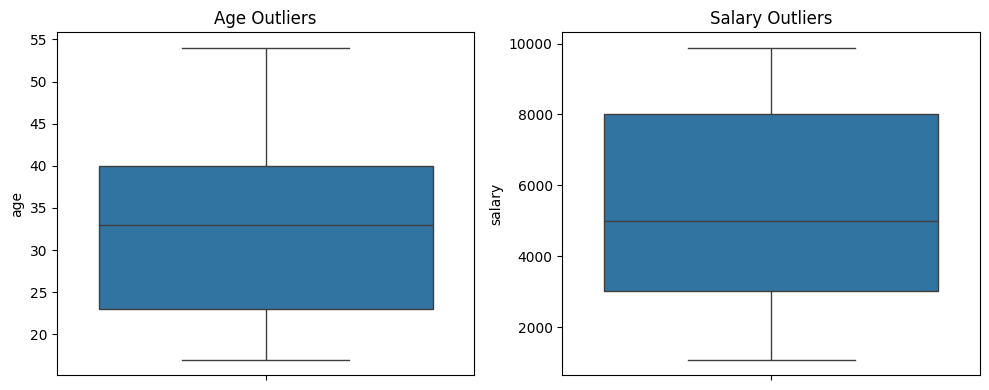

In [9]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['age'])
plt.title("Age Outliers")

plt.subplot(1, 2, 2)
sns.boxplot(y=df['salary'])
plt.title("Salary Outliers")

plt.tight_layout()
plt.show()

**Question 6: Treat missing values using mean, median and mode.**

In [10]:
# Numerical columns: replace missing values with median
df['age'] = df['age'].fillna(df['age'].median())

df['salary'] = df['salary'].fillna(df['salary'].median())

# Categorical columns: replace missing values with mode
df['company'] = df['company'].fillna(
    df['company'].mode()[0]
)

df['place'] = df['place'].fillna(
    df['place'].mode()[0]
)

# Check missing values after treatment
print(df.isnull().sum())

# Display cleaned dataset
print(df.head())

print("Final shape:", df.shape)

company    0
age        0
salary     0
place      0
country    0
gender     0
dtype: int64
   company   age  salary    place country  gender
0      TCS  20.0  5000.0  Chennai   India       0
1  Infosys  30.0  5000.0   Mumbai   India       0
2      TCS  35.0  2300.0  Kolkata   India       0
3  Infosys  40.0  3000.0    Delhi   India       0
4      TCS  23.0  4000.0   Mumbai   India       0
Final shape: (144, 6)


# 3.Data Analysis

**Question 1: Filter the data with age greater than 40 and salary less than 5000.**

In [11]:
# Filter employees
filtered_data = df[
    (df['age'] > 40) &
    (df['salary'] < 5000)
]

print(filtered_data)

     company   age  salary      place country  gender
21   Infosys  50.0  3184.0      Delhi   India       0
32   Infosys  45.0  4034.0    Kolkata   India       0
39   Infosys  41.0  3000.0     Mumbai   India       0
50   Infosys  41.0  3000.0    Chennai   India       0
57   Infosys  51.0  3184.0  Hyderabad   India       0
68   Infosys  43.0  4034.0     Mumbai   India       0
75   Infosys  44.0  3000.0     Cochin   India       0
86   Infosys  41.0  3000.0      Delhi   India       0
93   Infosys  54.0  3184.0     Mumbai   India       0
104  Infosys  44.0  4034.0      Delhi   India       0
122  Infosys  44.0  3234.0     Mumbai   India       0
129  Infosys  50.0  3184.0    Kolkata   India       0
138      CTS  44.0  3033.0     Cochin   India       0
140  Infosys  44.0  4034.0  Hyderabad   India       0
145  Infosys  44.0  4034.0      Delhi   India       1


**Question 2: Plot the chart with age and salary.**

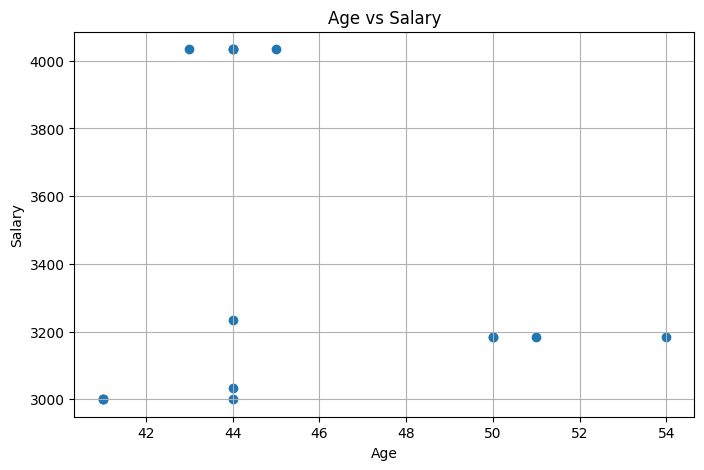

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(
    filtered_data['age'],
    filtered_data['salary']
)

plt.xlabel("Age")
plt.ylabel("Salary")
plt.title("Age vs Salary")

plt.grid()
plt.show()

**Question 3: Count the number of people from each place and represent it visually.**

Place
Mumbai        37
Calcutta      33
Chennai       14
Delhi         14
Cochin        13
Noida          8
Hyderabad      8
Podicherry     3
Pune           2
Bhopal         1
Nagpur         1
Name: count, dtype: int64


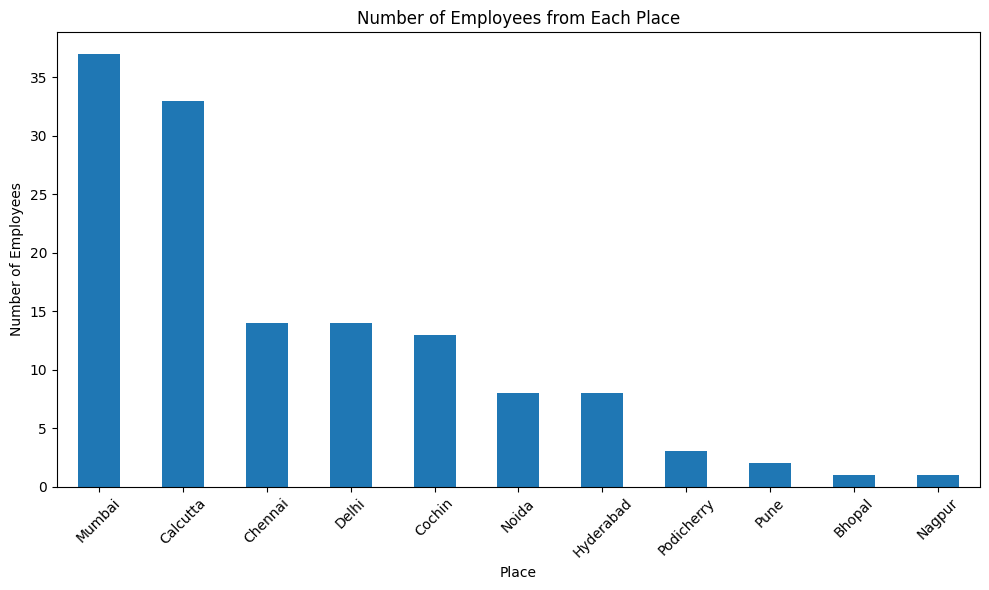

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Count employees from each place
df = pd.read_csv("Employee.csv")
place_count = df['Place'].value_counts()

print(place_count)

# Visualize the count
plt.figure(figsize=(10, 6))

place_count.plot(kind='bar')

plt.xlabel("Place")
plt.ylabel("Number of Employees")
plt.title("Number of Employees from Each Place")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 4. Data Encoding

In [5]:
# Select categorical columns (matching the capitalized columns in the current df)
categorical_columns = ['Company', 'Place', 'Country']

# Apply One-Hot Encoding
df_encoded = pd.get_dummies(
    df,
    columns=categorical_columns,
    dtype=int
)

# Display encoded dataset
print(df_encoded.head())

# Display columns
print(df_encoded.columns)

    Age  Salary  Gender  Company_CTS  Company_Congnizant  Company_Infosys  \
0  20.0     NaN       0            0                   0                0   
1  30.0     NaN       0            0                   0                1   
2  35.0  2300.0       0            0                   0                0   
3  40.0  3000.0       0            0                   0                1   
4  23.0  4000.0       0            0                   0                0   

   Company_Infosys Pvt Lmt  Company_TCS  Company_Tata Consultancy Services  \
0                        0            1                                  0   
1                        0            0                                  0   
2                        0            1                                  0   
3                        0            0                                  0   
4                        0            1                                  0   

   Place_Bhopal  ...  Place_Chennai  Place_Cochin  Place_Delhi  \
0 

# 5. Feature Scaling

**Question 1: StandardScaler**

In [6]:
from sklearn.preprocessing import StandardScaler

# Create StandardScaler object
scaler = StandardScaler()

# Apply StandardScaler
standard_scaled = scaler.fit_transform(df_encoded)

# Convert into DataFrame
standard_df = pd.DataFrame(standard_scaled,columns=df_encoded.columns)

print(standard_df.head())

        Age    Salary    Gender  Company_CTS  Company_Congnizant  \
0 -0.948501       NaN -0.535683    -0.566947           -0.117041   
1 -0.043841       NaN -0.535683    -0.566947           -0.117041   
2  0.408489 -1.175200 -0.535683    -0.566947           -0.117041   
3  0.860819 -0.902122 -0.535683    -0.566947           -0.117041   
4 -0.677103 -0.512010 -0.535683    -0.566947           -0.117041   

   Company_Infosys  Company_Infosys Pvt Lmt  Company_TCS  \
0        -0.660979                -0.117041     1.338825   
1         1.512907                -0.117041    -0.746924   
2        -0.660979                -0.117041     1.338825   
3         1.512907                -0.117041    -0.746924   
4        -0.660979                -0.117041     1.338825   

   Company_Tata Consultancy Services  Place_Bhopal  ...  Place_Chennai  \
0                          -0.117041     -0.082479  ...       3.093773   
1                          -0.117041     -0.082479  ...      -0.323230   
2       

**Question 2: MinMaxScaler**

In [7]:
from sklearn.preprocessing import MinMaxScaler

# Create MinMaxScaler object
minmax = MinMaxScaler()

# Apply MinMaxScaler
minmax_scaled = minmax.fit_transform(df_encoded)

# Convert into DataFrame
minmax_df = pd.DataFrame(minmax_scaled, columns=df_encoded.columns)
print(minmax_df.head())

        Age    Salary  Gender  Company_CTS  Company_Congnizant  \
0  0.370370       NaN     0.0          0.0                 0.0   
1  0.555556       NaN     0.0          0.0                 0.0   
2  0.648148  0.137817     0.0          0.0                 0.0   
3  0.740741  0.217480     0.0          0.0                 0.0   
4  0.425926  0.331285     0.0          0.0                 0.0   

   Company_Infosys  Company_Infosys Pvt Lmt  Company_TCS  \
0              0.0                      0.0          1.0   
1              1.0                      0.0          0.0   
2              0.0                      0.0          1.0   
3              1.0                      0.0          0.0   
4              0.0                      0.0          1.0   

   Company_Tata Consultancy Services  Place_Bhopal  ...  Place_Chennai  \
0                                0.0           0.0  ...            1.0   
1                                0.0           0.0  ...            0.0   
2                   

**Question 3: Compare both scaling techniques**

In [8]:
print("StandardScaler Result:")
print(standard_df.describe())

print("\nMinMaxScaler Result:")
print(minmax_df.describe())

StandardScaler Result:
                Age        Salary        Gender   Company_CTS  \
count  1.300000e+02  1.240000e+02  1.480000e+02  1.480000e+02   
mean   2.732857e-17 -1.074409e-17 -8.401688e-17  3.000603e-18   
std    1.003868e+00  1.004057e+00  1.003396e+00  1.003396e+00   
min   -2.757821e+00 -1.647626e+00 -5.356832e-01 -5.669467e-01   
25%   -7.675691e-01 -8.904183e-01 -5.356832e-01 -5.669467e-01   
50%    1.823238e-01 -1.218975e-01 -5.356832e-01 -5.669467e-01   
75%    6.572702e-01  1.048439e+00 -5.356832e-01 -5.669467e-01   
max    2.127342e+00  1.780289e+00  1.866775e+00  1.763834e+00   

       Company_Congnizant  Company_Infosys  Company_Infosys Pvt Lmt  \
count        1.480000e+02     1.480000e+02             1.480000e+02   
mean        -1.800362e-17    -7.351477e-17            -1.800362e-17   
std          1.003396e+00     1.003396e+00             1.003396e+00   
min         -1.170411e-01    -6.609790e-01            -1.170411e-01   
25%         -1.170411e-01    -6.6097